# Franka in Isaac Lab: VLM grounding + scripted grasping
### Where do pick failures come from (the VLM, perception, the grasp, or the controller), and how does VLM size matter?

**Setup in one line.** A Franka Panda with the standard Franka Hand stands at a table with 6 random YCB objects. An external RGB-D camera (RealSense D435 intrinsics) and a wrist RGB-D camera observe the scene. The instruction is *"pick up the ⟨object⟩"*. The pipeline:
1. depth clustering proposes candidate objects;
2. a local VLM picks which candidate is the target;
3. a scripted top-down grasp is planned from the object's points;
4. our numpy IK turns each move into a joint trajectory, which the robot executes.

**Built to move to the real arm.** Everything above the `Robot` interface (perception, VLM, grasp planner, IK, episode logic) is shared between the Isaac backend and the real-robot backend (franky + RealSense, `vrg/franka/real_franky.py`). The simulator only adds an *oracle*: ground-truth masks and object poses, used to score episodes and to attribute failures, never by the method.

**Protocol.**
* Scenes are seeds; every graspable object in a scene is the target once.
* **Dev** = seeds 0–9 (used to debug and to pick each VLM's grounding mode).
* **Eval** = seeds 100–149, 257 episodes per configuration, untouched during development.
* Brackets are Wilson 95% CIs.

In [1]:
import json, os, glob, math, collections
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Video, Image
ROOT = os.path.abspath('..'); RUNS = f'{ROOT}/runs/franka'
INK, INK2, GRID = '#0b0b0b', '#52514e', '#e4e3df'
plt.rcParams.update({'figure.dpi': 110, 'font.size': 10, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
                     'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6,
                     'axes.axisbelow': True, 'figure.facecolor': 'white', 'legend.frameon': False})
def load(name):
    p = f'{RUNS}/{name}/results.json'; return json.load(open(p)) if os.path.exists(p) else []
def wilson(k, n, z=1.96):
    if n == 0: return (np.nan, np.nan)
    p = k / n; d = 1 + z*z/n; c = (p + z*z/(2*n)) / d; h = z*math.sqrt(p*(1-p)/n + z*z/(4*n*n)) / d; return c - h, c + h
def rate(R, key='success'):
    k, n = sum(bool(r.get(key)) for r in R), len(R); lo, hi = wilson(k, n); return dict(sr=k/n if n else np.nan, lo=lo, hi=hi, n=n, k=k)
def fmt(R, key='success'):
    s = rate(R, key); return 'pending' if s['n'] == 0 else f"{100*s['sr']:.1f}% [{100*s['lo']:.0f}–{100*s['hi']:.0f}] (n={s['n']})"
def table(rows, header):
    out = '| ' + ' | '.join(header) + ' |\n|' + '---|' * len(header) + '\n'
    for r in rows: out += '| ' + ' | '.join(str(x) for x in r) + ' |\n'
    display(Markdown(out))
def show(path, w=640, caption=None):
    if os.path.exists(path):
        if caption: display(Markdown(caption))
        display(Video(path, embed=True, width=w, html_attributes='controls loop muted'))
FAILS = ['segmentation', 'grounding', 'grasp_plan', 'ik', 'ik_lift', 'approach_collision', 'reach', 'grasp_miss', 'grasp_slip', 'wrong_object']
FC = {'success': '#2a78d6', 'segmentation': '#8a8984', 'grounding': '#eb6834', 'grasp_plan': '#c3c2b7', 'ik': '#52514e', 'ik_lift': '#3a3936',
      'approach_collision': '#eda100', 'reach': '#b8860b', 'grasp_miss': '#1baf7a', 'grasp_slip': '#0e7a55', 'wrong_object': '#a83232', 'other': '#dddddd'}
print('runs:', sorted(os.listdir(RUNS)) if os.path.isdir(RUNS) else 'none')

runs: ['dev_probe2_2b', 'dev_probe2_32b', 'dev_probe2_4b', 'dev_probe2_8b', 'dev_probe_2b', 'dev_probe_32b', 'dev_probe_4b', 'dev_probe_8b', 'e1_a_extonly', 'e1_b_refine', 'e1_c_fixedyaw', 'e1_d_joint', 'e1_e_native', 'e1_f_gtseg', 'e3_qwen3vl-2b', 'e3_qwen3vl-32b', 'e3_qwen3vl-4b', 'e3_qwen3vl-8b', 'ground_eval', 'rx_2b_ens1_K2', 'rx_2b_ens3_K0', 'rx_2b_ens3_K2', 'rx_2b_ens3_K4', 'rx_2b_gate_last', 'rx_2b_gate_vote', 'rx_32b_ens1_K2', 'rx_32b_ens3_K0', 'rx_32b_ens3_K2', 'rx_32b_ens3_K4', 'rx_32b_gate_last', 'rx_32b_gate_vote', 'rx_4b_ens1_K2', 'rx_4b_ens3_K0', 'rx_4b_ens3_K2', 'rx_4b_ens3_K4', 'rx_4b_gate_last', 'rx_4b_gate_vote', 'rx_8b_ens1_K2', 'rx_8b_ens3_K0', 'rx_8b_ens3_K2', 'rx_8b_ens3_K4', 'rx_8b_gate_last', 'rx_8b_gate_vote']


---
## 1. Setup: a simulator that mirrors the real cell

| | Simulation (Isaac Lab 2.3 / Isaac Sim 5.1) | Real robot (planned) |
|---|---|---|
| Arm, gripper | Franka Panda, Franka Hand (Isaac Lab asset), PD joint control, gravity-compensated | Franka via FCI with **franky** (libfranka), Franka Hand |
| External camera | RGB-D 640×480, fx = fy = 615 px (D435 colour intrinsics), on a "tripod" opposite the robot | RealSense D435/D455; extrinsics from calibration (`calib.json`) |
| Wrist camera | RGB-D on the hand, 6.5 cm off-axis, parallel to the fingers | RealSense on the hand; hand-eye calibration |
| Objects | 6 random YCB objects per scene, dropped and settled at random yaw | the physical YCB set (same objects) |
| Motion | joint trajectories from our IK, sent as joint position targets at 100 Hz | the same trajectories, as franky joint waypoints |

**Code map** (`vrg/franka/`):
* `core.py`: interface and types;
* `kinematics.py`: Panda forward kinematics, Jacobian, damped-least-squares IK, joint and Cartesian planners;
* `perception.py`: table fit, object proposals, top-down grasp;
* `vlm.py`: the three grounding modes;
* `episode.py`: the backend-agnostic episode loop;
* `reactive.py`: reactive grounding (re-asking the VLM along the approach); `vlm_server.py` / `vlm_client.py` serve the VLM to the robot process over a socket;
* `isaac_backend.py` and `real_franky.py`: the two backends;
* `run_isaac.py` and `ground_offline.py`: experiment drivers.

**Sanity checks.**
* The numpy kinematics match Isaac's TCP to 0.0 mm and 0.0 rad at the home pose.
* IK solves 200/200 random reachable poses in about 1 ms each.
* The joint-trajectory tracking error at the end of a move is about 2–4 mm.

**Engineering note.** CPU PhysX is about 36× faster than GPU PhysX for one robot and a few objects (0.5 vs 18 ms per step); rendering stays on the GPU.

A random evaluation scene from the external camera:

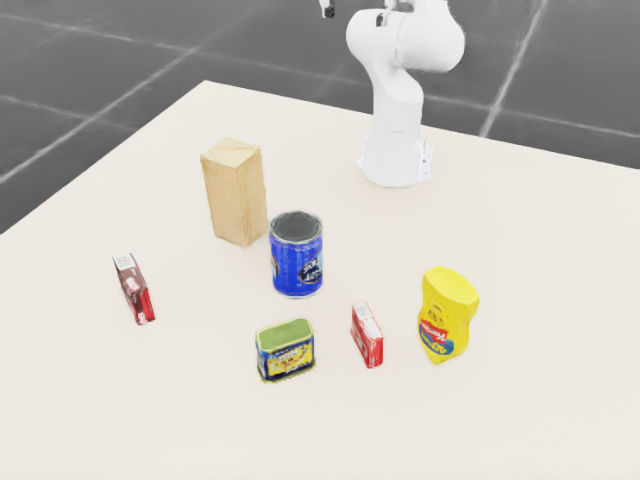

In [2]:
p = f'{ROOT}/demo/franka/scene.png'
if os.path.exists(p): display(Markdown('A random evaluation scene from the external camera:')); display(Image(p, width=560))

### The pipeline and how a failure is attributed

Each episode records the outcome of every stage, and the **first** broken stage is its failure label:

| Stage | Failure label | Meaning |
|---|---|---|
| perception | `segmentation` | no depth proposal is (mostly) the target object |
| grounding (VLM) | `grounding` | the chosen proposal is a different object |
| grasp planning | `grasp_plan` | the object is wider than the 8 cm Franka Hand from above |
| IK | `ik`, `ik_lift` | no joint solution for the pre-grasp, approach or lift |
| approach | `approach_collision` | the fingers hit the target or a neighbour before closing (TCP stopped > 1 cm short and something moved) |
| controller | `reach` | the TCP ended > 1 cm from the goal with nothing disturbed (tracking error) |
| grasp | `grasp_miss` / `grasp_slip` / `wrong_object` | closed on nothing / held but dropped when lifting / lifted something else |

Success means the target ended up more than 5 cm above where it started.

---
## 2. The grasp and the controller, with a perfect VLM

To separate the robot side from the VLM, these runs use **oracle grounding**: the proposal that ground truth says is the target. Perception is still the real depth-clustering pipeline (except in config f).

| Config | Perception | Grasp | Controller |
|---|---|---|---|
| a | external camera only | top-down, angle from footprint PCA | joint move to pre-grasp, straight-line approach and lift (our IK) |
| b | **+ wrist "look" before grasping** | same | same |
| c | + look | **fixed angle** (no PCA) | same |
| d | + look | PCA | **joint-space** moves only (curved TCP path) |
| e | + look | PCA | **Isaac's DifferentialIK (DLS)** tracking the goal pose directly |
| f | + look, **ground-truth segmentation** | PCA | straight-line |

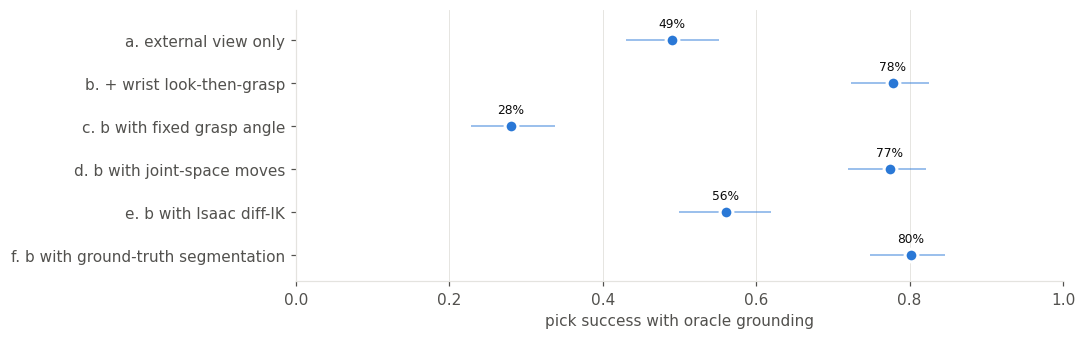

| Config | Success | median TCP error at grasp pose | wall time / episode |
|---|---|---|---|
| a. external view only | 49.0% [43–55] (n=257) | 4.1 mm | 2.0 s |
| b. + wrist look-then-grasp | 77.8% [72–82] (n=257) | 3.4 mm | 3.0 s |
| c. b with fixed grasp angle | 28.0% [23–34] (n=257) | 3.5 mm | 1.7 s |
| d. b with joint-space moves | 77.4% [72–82] (n=257) | 3.6 mm | 2.1 s |
| e. b with Isaac diff-IK | 56.0% [50–62] (n=257) | 2.9 mm | 2.2 s |
| f. b with ground-truth segmentation | 80.2% [75–85] (n=257) | 3.4 mm | 2.3 s |


In [3]:
E1 = [('a. external view only', 'e1_a_extonly'), ('b. + wrist look-then-grasp', 'e1_b_refine'), ('c. b with fixed grasp angle', 'e1_c_fixedyaw'),
      ('d. b with joint-space moves', 'e1_d_joint'), ('e. b with Isaac diff-IK', 'e1_e_native'), ('f. b with ground-truth segmentation', 'e1_f_gtseg')]
fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (lab, run) in enumerate(E1[::-1]):
    r = rate(load(run))
    if not r['n']: ax.text(0.01, i, 'pending', va='center', fontsize=8, color=INK2); continue
    ax.errorbar(r['sr'], i, xerr=[[r['sr'] - r['lo']], [r['hi'] - r['sr']]], fmt='none', ecolor='#2a78d6', elinewidth=1, alpha=0.6)
    ax.scatter(r['sr'], i, s=70, color='#2a78d6', edgecolors='white', linewidths=2, zorder=3)
    ax.text(r['sr'], i + 0.3, f"{100*r['sr']:.0f}%", ha='center', fontsize=8, color=INK)
ax.set_yticks(range(len(E1))); ax.set_yticklabels([l for l, _ in E1[::-1]]); ax.set_xlim(0, 1); ax.set_ylim(-0.6, len(E1) - 0.3)
ax.set_xlabel('pick success with oracle grounding'); ax.grid(axis='y', visible=False); plt.show()
table([[l, fmt(load(r)), f"{np.nanmedian([x.get('reach_err', np.nan) for x in load(r)])*1000:.1f} mm" if load(r) else '–',
        f"{np.mean([x['sec'] for x in load(r)]):.1f} s" if load(r) else '–'] for l, r in E1],
      ['Config', 'Success', 'median TCP error at grasp pose', 'wall time / episode'])

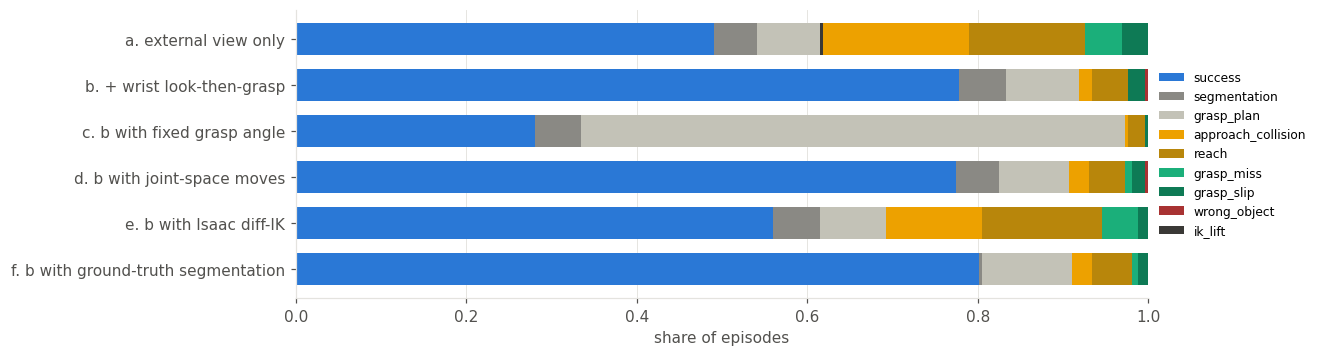

| Config | segmentation | grounding | grasp_plan | ik | ik_lift | approach_collision | reach | grasp_miss | grasp_slip | wrong_object |
|---|---|---|---|---|---|---|---|---|---|---|
| a. external view only | 13 | 0 | 19 | 0 | 1 | 44 | 35 | 11 | 8 | 0 |
| b. + wrist look-then-grasp | 14 | 0 | 22 | 0 | 0 | 4 | 11 | 0 | 5 | 1 |
| c. b with fixed grasp angle | 14 | 0 | 164 | 0 | 0 | 1 | 5 | 0 | 1 | 0 |
| d. b with joint-space moves | 13 | 0 | 21 | 0 | 0 | 6 | 11 | 2 | 4 | 1 |
| e. b with Isaac diff-IK | 14 | 0 | 20 | 0 | 0 | 29 | 36 | 11 | 3 | 0 |
| f. b with ground-truth segmentation | 1 | 0 | 27 | 0 | 0 | 6 | 12 | 2 | 3 | 0 |


In [4]:
# First broken stage, per config
fig, ax = plt.subplots(figsize=(10, 3.4))
for i, (lab, run) in enumerate(E1[::-1]):
    R = load(run)
    if not R: continue
    c = collections.Counter('success' if x.get('success') else (x['fail'] if x['fail'] in FC else 'other') for x in R); left = 0
    for k in ['success'] + FAILS + ['other']:
        v = c.get(k, 0) / len(R)
        if v: ax.barh(i, v, left=left, color=FC[k], height=0.7, label=k if k not in ax.get_legend_handles_labels()[1] else None); left += v
ax.set_yticks(range(len(E1))); ax.set_yticklabels([l for l, _ in E1[::-1]]); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(loc='center left', bbox_to_anchor=(1.0, 0.5), fontsize=8); ax.set_xlabel('share of episodes'); plt.show()
table([[l] + [collections.Counter(x['fail'] for x in load(r) if not x.get('success')).get(k, 0) for k in FAILS] for l, r in E1 if load(r)], ['Config'] + FAILS)

In [5]:
# Per object (config b): which objects are hard for a top-down scripted grasp?
R = load('e1_b_refine')
if R:
    by = collections.defaultdict(list)
    for x in R: by[x['target']].append(x)
    rows = sorted(by.items(), key=lambda kv: -np.mean([bool(x.get('success')) for x in kv[1]]))
    table([[k, f"{sum(bool(x.get('success')) for x in v)}/{len(v)}", ', '.join(f'{a} {b}' for a, b in collections.Counter(x['fail'] for x in v if not x.get('success')).most_common(3))]
           for k, v in rows], ['Object', 'Success (config b)', 'Main failures'])

| Object | Success (config b) | Main failures |
|---|---|---|
| pudding box | 13/13 |  |
| bleach bottle | 25/27 | grasp_plan 1, segmentation 1 |
| foam brick | 19/21 | approach_collision 1, segmentation 1 |
| sugar box | 18/20 | reach 1, segmentation 1 |
| tomato soup can | 18/20 | reach 2 |
| mustard bottle | 15/18 | reach 2, grasp_plan 1 |
| marker | 15/18 | reach 2, segmentation 1 |
| potted meat can | 18/22 | grasp_plan 2, approach_collision 1, grasp_slip 1 |
| banana | 17/22 | grasp_plan 3, approach_collision 1, segmentation 1 |
| gelatin box | 16/22 | reach 3, segmentation 2, wrong_object 1 |
| clamp | 11/19 | grasp_slip 4, segmentation 2, grasp_plan 1 |
| cracker box | 9/19 | grasp_plan 10 |
| scissors | 6/16 | segmentation 5, grasp_plan 4, approach_collision 1 |


**Reading section 2.**
* **The wrist look matters most: 49% → 78%.** The external camera sees objects from about 1.1 m at 640×480, so its point clouds are partial (one side only) and its grasp centres and angles are off by up to a few cm. That shows up as `approach_collision` (44: the fingers come down on the object) and `reach` (35). One extra stop 22 cm above the object to re-segment it from the wrist camera removes most of both.
* **The grasp angle has to come from the object: fixed angle 28%.** With PCA the gripper closes across the narrow side. With a fixed angle, most objects are wider than the planner's 7.5 cm opening limit along that direction, and the planner refuses (`grasp_plan` 164).
* **Our IK beats Isaac's differential IK (78% vs 56%) on the same targets.** Isaac's `DifferentialIKController` (one damped least-squares step per control tick, toward the final goal) often stalls 4–5 cm short with the hand tilted when the goal asks for a large wrist rotation (see the `e1_e_native` videos). Our controller plans first:
  * IK at the goal with joint limits, a null-space posture term and random restarts;
  * then a minimum-jerk joint path to the pre-grasp pose, and a straight Cartesian line (IK per waypoint) for the approach and lift.

  When both controllers converge, they are equally precise (median TCP error about 3 mm in the table). The difference is the tail: diff-IK ends more than 1 cm off, or hits the object on the way, in 65 episodes (`reach` 36 + `approach_collision` 29), against 15 for ours. Joint-space moves for every segment do as well (77%), so in sim the straight-line approach doesn't buy much. It should matter more on the real arm next to other objects.
* **Perception is a small part of the gap: ground-truth segmentation adds 2 points (80%).** What's left is mostly the grasp itself, as a top-down parallel-jaw grasp:
  * the **cracker box** (10/19 `grasp_plan`) lies flat and is wider than the hand in every direction from above;
  * the **scissors** and **clamp** are thin or segment poorly, and the clamp slips;
  * everything compact (cans, small boxes, bottles, foam brick) succeeds 85–100% of the time.

  Side grasps for wide objects would be the next robot-side gain.

---
## 3. VLM size: does a bigger model ground better?

Qwen3-VL **2B, 4B, 8B and 32B** (same family, all local) see exactly the same saved evaluation observations: 257 episodes from config b. Each model answers in three modes:
* **point**: "Point to the X" on the full external image; the proposal under (or nearest) the point wins.
* **marks**: proposals are numbered on the image (set-of-marks), and the model answers with a number.
* **verify**: each proposal is cropped and zoomed, and the model's Yes/No logit for "is this the X?" ranks them.

Accuracy is the share of episodes where the chosen proposal is the target. *Given segmented* conditions on the target having a proposal at all, which isolates the VLM from perception.

Proposals are labelled with the ground-truth labels from the live run, which fuse the external and wrist cameras. In 12 of 257 scenes, the external camera's instance segmentation lagged its RGB/depth by one render while an object was still settling, so ext-only labels missed the target in 6 scenes. Rescoring with the live labels raised every model's accuracy by about 2 points, and the ranking did not change. `isaac_backend.frames()` now renders twice before capturing.

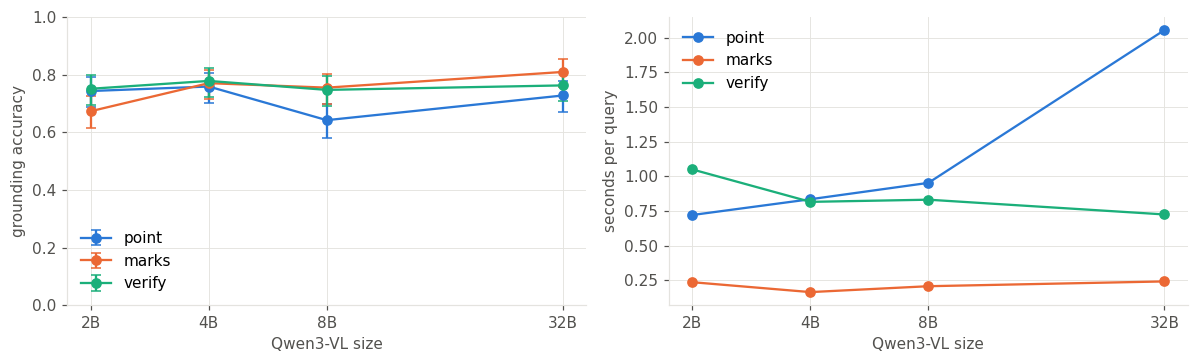

| Model | Mode | Accuracy | Accuracy given segmented | Latency |
|---|---|---|---|---|
| qwen3vl-2b | point | 74.3% [69–79] (n=257) | 78.6% [73–83] (n=243) | 0.72 s |
| qwen3vl-2b | marks | 67.3% [61–73] (n=257) | 71.2% [65–77] (n=243) | 0.24 s |
| qwen3vl-2b | verify | 75.1% [69–80] (n=257) | 79.4% [74–84] (n=243) | 1.05 s |
| qwen3vl-4b | point | 75.9% [70–81] (n=257) | 80.2% [75–85] (n=243) | 0.83 s |
| qwen3vl-4b | marks | 77.0% [72–82] (n=257) | 81.5% [76–86] (n=243) | 0.16 s |
| qwen3vl-4b | verify | 77.8% [72–82] (n=257) | 82.3% [77–87] (n=243) | 0.82 s |
| qwen3vl-8b | point | 64.2% [58–70] (n=257) | 67.9% [62–73] (n=243) | 0.95 s |
| qwen3vl-8b | marks | 75.5% [70–80] (n=257) | 79.8% [74–84] (n=243) | 0.21 s |
| qwen3vl-8b | verify | 74.7% [69–80] (n=257) | 79.0% [73–84] (n=243) | 0.83 s |
| qwen3vl-32b | point | 72.8% [67–78] (n=257) | 77.0% [71–82] (n=243) | 2.06 s |
| qwen3vl-32b | marks | 80.9% [76–85] (n=257) | 85.6% [81–89] (n=243) | 0.24 s |
| qwen3vl-32b | verify | 76.3% [71–81] (n=257) | 80.7% [75–85] (n=243) | 0.72 s |


In [6]:
G = {}
BEST = json.load(open(f'{RUNS}/ground_eval/best_mode_dev.json')) if os.path.exists(f'{RUNS}/ground_eval/best_mode_dev.json') else {}
for f in glob.glob(f'{RUNS}/ground_eval/qwen3vl-*_*.json'):
    m, mode = os.path.basename(f)[:-5].rsplit('_', 1); G[(m, mode)] = json.load(open(f))
MODELS = [m for m in ['qwen3vl-2b', 'qwen3vl-4b', 'qwen3vl-8b', 'qwen3vl-32b'] if any(k[0] == m for k in G)]
SIZE = {'qwen3vl-2b': 2, 'qwen3vl-4b': 4, 'qwen3vl-8b': 8, 'qwen3vl-32b': 32}
MC = {'point': '#2a78d6', 'marks': '#eb6834', 'verify': '#1baf7a'}
if G:
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4))
    for mode, col in MC.items():
        xs, ys, lo, hi, ts = [], [], [], [], []
        for m in MODELS:
            R = list(G.get((m, mode), {}).values())
            if not R: continue
            k = sum(r['correct'] for r in R); a, b = wilson(k, len(R)); xs.append(SIZE[m]); ys.append(k / len(R)); lo.append(a); hi.append(b)
            ts.append(np.mean([r['sec'] for r in R]))
        if not xs: continue
        ys, lo, hi = map(np.array, (ys, lo, hi))
        axs[0].errorbar(xs, ys, yerr=[ys - lo, hi - ys], color=col, marker='o', capsize=3, label=mode)
        axs[1].plot(xs, ts, color=col, marker='o', label=mode)
    for ax in axs: ax.set_xscale('log', base=2); ax.set_xticks([2, 4, 8, 32]); ax.set_xticklabels(['2B', '4B', '8B', '32B']); ax.set_xlabel('Qwen3-VL size')
    axs[0].set_ylabel('grounding accuracy'); axs[0].set_ylim(0, 1); axs[0].legend(); axs[1].set_ylabel('seconds per query'); axs[1].legend()
    plt.tight_layout(); plt.show()
    table([[m, mode, fmt([{'success': r['correct']} for r in G[(m, mode)].values()]),
            fmt([{'success': r['correct']} for r in G[(m, mode)].values() if r['segmented']]), f"{np.mean([r['sec'] for r in G[(m, mode)].values()]):.2f} s"]
           for m in MODELS for mode in MC if (m, mode) in G], ['Model', 'Mode', 'Accuracy', 'Accuracy given segmented', 'Latency'])

### Size vs inference cost

Each model was profiled alone on one GPU (`vrg/franka/vlm_profile.py`: bf16, Hugging Face `generate`, greedy decoding, no batching, 20 eval scenes after one warm-up query). These latencies are lower than the sweep's, which shared the GPU with Isaac runs.
* *point*: generates a JSON point, about 25 tokens.
* *marks*: generates a one-token number.
* *verify*: one forward pass per proposal (6 on average), with no generation.

Accuracy is on the 257 eval scenes. Closed-loop success uses each model's dev-chosen mode.

| Model | Params | Peak GPU memory | point latency | marks latency | verify latency | Best grounding accuracy | Closed-loop success |
|---|---|---|---|---|---|---|---|
| qwen3vl-2b | 2.1 B | 4 GB | 0.29 s | 0.04 s | 0.18 s | 75% (verify) | 63% (point) |
| qwen3vl-4b | 4.4 B | 8 GB | 0.46 s | 0.06 s | 0.21 s | 78% (verify) | 64% (point) |
| qwen3vl-8b | 8.8 B | 16 GB | 0.60 s | 0.08 s | 0.28 s | 75% (marks) | 64% (verify) |
| qwen3vl-32b | 33.4 B | 62 GB | 1.91 s | 0.23 s | 0.75 s | 81% (marks) | 68% (marks) |


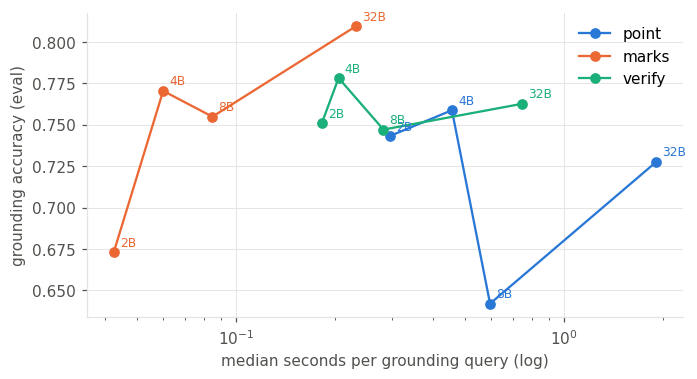

In [7]:
PROF = json.load(open(f'{RUNS}/ground_eval/vlm_profile.json')) if os.path.exists(f'{RUNS}/ground_eval/vlm_profile.json') else {}
if PROF:
    rows = []
    for m in MODELS:
        p = PROF[m]; acc = {mode: np.mean([r['correct'] for r in G[(m, mode)].values()]) for mode in MC if (m, mode) in G}; bm = max(acc, key=acc.get)
        cl = load(f'e3_{m}')
        rows.append([m, f"{p['params_b']:.1f} B", f"{p['peak_gpu_gb']:.0f} GB"] + [f"{p[f'{mode}_s_median']:.2f} s" for mode in MC]
                    + [f"{100*acc[bm]:.0f}% ({bm})", f"{100*rate(cl)['sr']:.0f}% ({BEST.get(m, '?')})" if cl else '–'])
    table(rows, ['Model', 'Params', 'Peak GPU memory', 'point latency', 'marks latency', 'verify latency', 'Best grounding accuracy', 'Closed-loop success'])
    fig, ax = plt.subplots(figsize=(7, 3.6))
    for mode, col in MC.items():
        xs = [PROF[m][f'{mode}_s_median'] for m in MODELS]; ys = [np.mean([r['correct'] for r in G[(m, mode)].values()]) for m in MODELS]
        ax.plot(xs, ys, color=col, marker='o', label=mode)
        for x, y, m in zip(xs, ys, MODELS): ax.annotate(m.split('-')[1].upper(), (x, y), textcoords='offset points', xytext=(4, 4), fontsize=8, color=col)
    ax.set_xscale('log'); ax.set_xlabel('median seconds per grounding query (log)'); ax.set_ylabel('grounding accuracy (eval)'); ax.legend(); plt.show()

In [8]:
# Which objects does the VLM confuse? (best mode per model, chosen on dev scenes)
BEST = json.load(open(f'{RUNS}/ground_eval/best_mode_dev.json')) if os.path.exists(f'{RUNS}/ground_eval/best_mode_dev.json') else {}
for m in MODELS:
    mode = BEST.get(m)
    if (m, mode) not in G: continue
    c = collections.Counter((k.split('|')[1], r['chosen_obj']) for k, r in G[(m, mode)].items() if not r['correct'])
    display(Markdown(f"**{m} ({mode})**, most common confusions (target → chosen): " + '; '.join(f'{a[4:]} → {str(b)[4:] if b else "nothing"} ×{n}' for (a, b), n in c.most_common(6))))

**qwen3vl-2b (point)**, most common confusions (target → chosen): gelatin_box → potted_meat_can ×7; foam_brick → wood_block ×6; sugar_box → gelatin_box ×4; potted_meat_can → tomato_soup_can ×4; sugar_box → pudding_box ×4; potted_meat_can → master_chef_can ×3

**qwen3vl-4b (point)**, most common confusions (target → chosen): foam_brick → wood_block ×6; potted_meat_can → nothing ×5; gelatin_box → pudding_box ×4; gelatin_box → sugar_box ×3; sugar_box → gelatin_box ×3; mustard_bottle → nothing ×2

**qwen3vl-8b (verify)**, most common confusions (target → chosen): foam_brick → gelatin_box ×5; foam_brick → wood_block ×4; potted_meat_can → tomato_soup_can ×3; bleach_cleanser → sugar_box ×3; gelatin_box → pudding_box ×3; gelatin_box → mustard_bottle ×2

**qwen3vl-32b (marks)**, most common confusions (target → chosen): foam_brick → wood_block ×4; potted_meat_can → tomato_soup_can ×4; gelatin_box → foam_brick ×4; potted_meat_can → master_chef_can ×4; gelatin_box → pudding_box ×3; gelatin_box → cracker_box ×3

**What the models see and pick.** These are four evaluation scenes chosen to show typical errors. The external image is cropped to the objects. The target is outlined in green, and each dot is one model's pick, in its dev-chosen mode. Rendered by `vrg/franka/grounding_figs.py`.

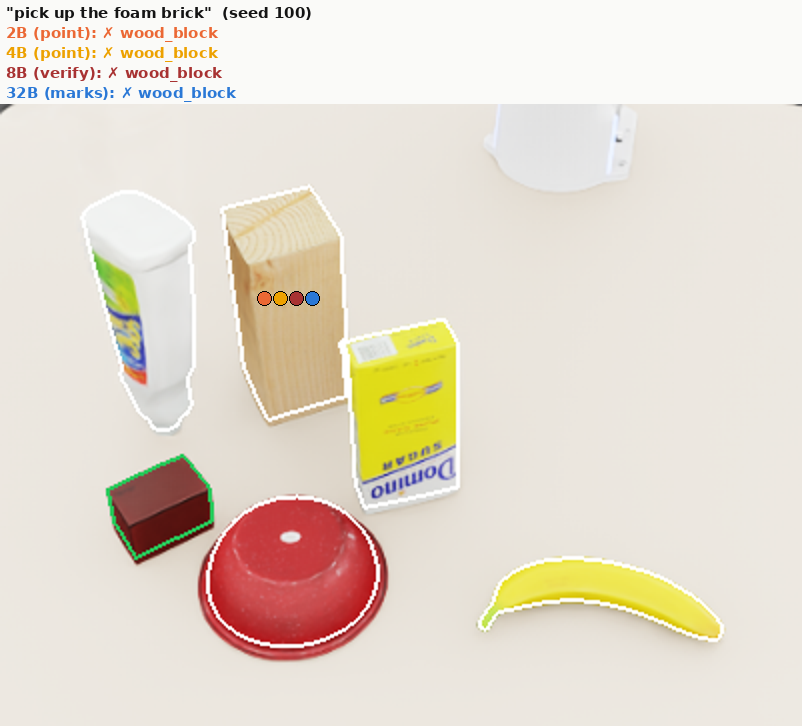

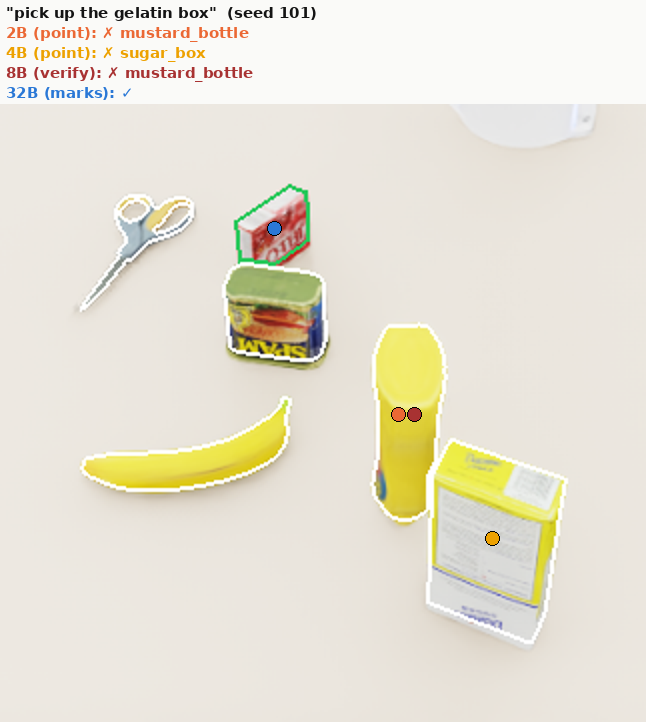

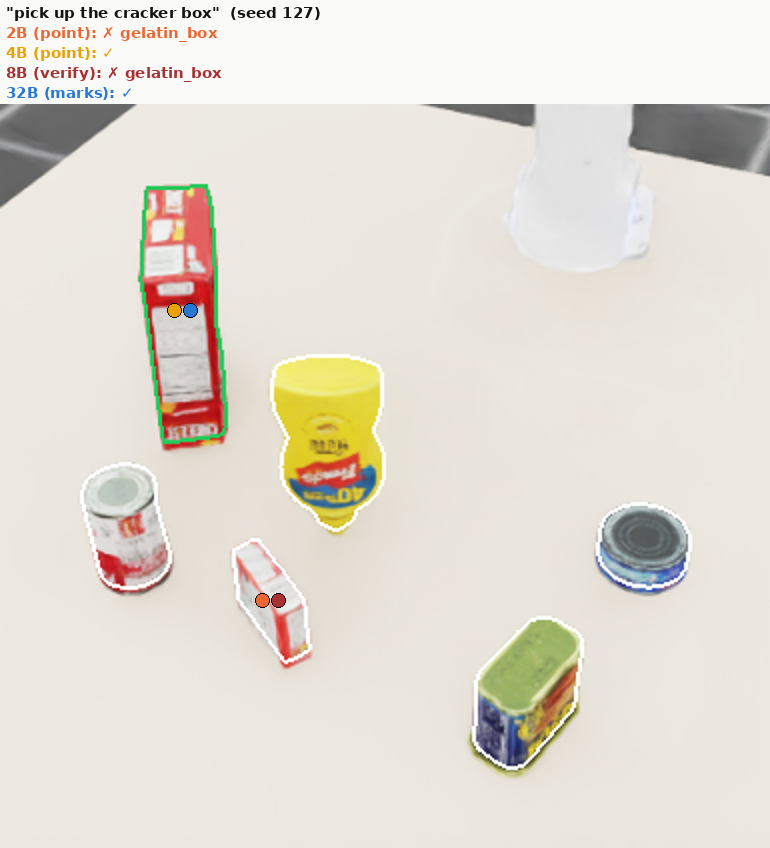

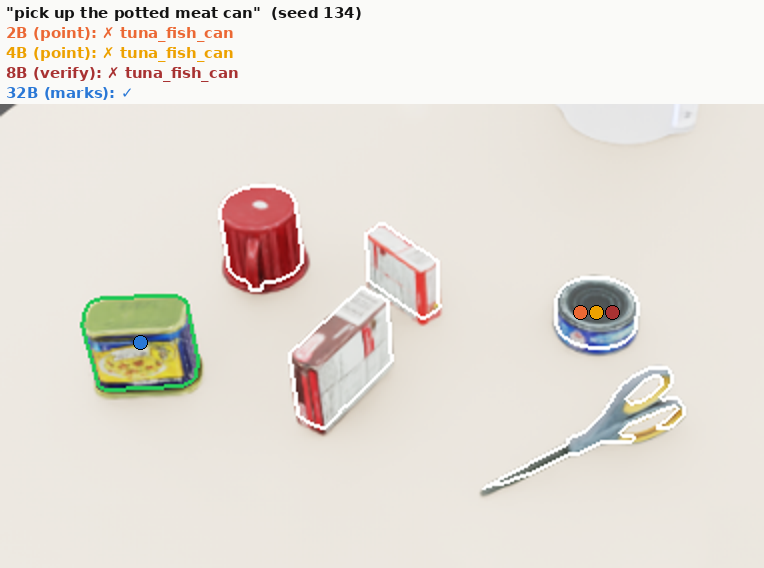

In [9]:
for f in sorted(glob.glob(f'{ROOT}/demo/franka/grounding/*.png')):
    display(Image(f, width=430))

---
## 4. Closed loop: who fails, the VLM or the grasp?

Full episodes with each model's VLM choices, using each model's best grounding mode as chosen **on the dev scenes**, with config b's perception, grasp and controller. Every failure is attributed to the first broken stage:
* the **VLM** (wrong object),
* **perception** (the target was never segmented),
* or the **robot side** (grasp plan, IK, approach collision, tracking, grasp miss or slip).

Oracle grounding is the upper bound.

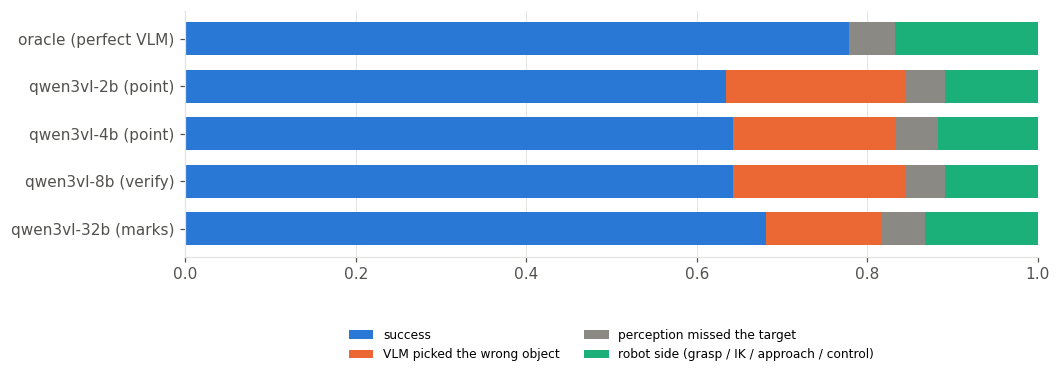

| Grounding | Success | failed: VLM | failed: perception | failed: robot side |
|---|---|---|---|---|
| qwen3vl-32b (marks) | 68.1% [62–73] (n=257) | 14% | 5% | 13% |
| qwen3vl-8b (verify) | 64.2% [58–70] (n=257) | 20% | 5% | 11% |
| qwen3vl-4b (point) | 64.2% [58–70] (n=257) | 19% | 5% | 12% |
| qwen3vl-2b (point) | 63.4% [57–69] (n=257) | 21% | 5% | 11% |
| oracle (perfect VLM) | 77.8% [72–82] (n=257) | 0% | 5% | 17% |


In [10]:
E3 = [('oracle (perfect VLM)', 'e1_b_refine')] + [(f'{m} ({BEST.get(m, "?")})', f'e3_{m}') for m in ['qwen3vl-2b', 'qwen3vl-4b', 'qwen3vl-8b', 'qwen3vl-32b']]
GROUP = {'grounding': 'VLM picked the wrong object', 'segmentation': 'perception missed the target'}
rows = []
fig, ax = plt.subplots(figsize=(10, 2.9))
for i, (lab, run) in enumerate(E3[::-1]):
    R = load(run)
    if not R: ax.text(0.01, i, 'pending', va='center', fontsize=8, color=INK2); continue
    c = collections.Counter('success' if x.get('success') else GROUP.get(x['fail'], 'robot side (grasp / IK / approach / control)') for x in R)
    left = 0
    for k, col in [('success', '#2a78d6'), ('VLM picked the wrong object', '#eb6834'), ('perception missed the target', '#8a8984'), ('robot side (grasp / IK / approach / control)', '#1baf7a')]:
        v = c.get(k, 0) / len(R); ax.barh(i, v, left=left, color=col, height=0.7, label=k if i == len(E3) - 1 else None); left += v
    rows.append([lab, fmt(R), f"{100*c.get('VLM picked the wrong object', 0)/len(R):.0f}%", f"{100*c.get('perception missed the target', 0)/len(R):.0f}%",
                 f"{100*c.get('robot side (grasp / IK / approach / control)', 0)/len(R):.0f}%"])
ax.set_yticks(range(len(E3))); ax.set_yticklabels([l for l, _ in E3[::-1]]); ax.set_xlim(0, 1); ax.grid(axis='y', visible=False)
ax.legend(loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2, fontsize=8); plt.show()
table(rows, ['Grounding', 'Success', 'failed: VLM', 'failed: perception', 'failed: robot side'])

**Reading sections 3 and 4.**
* **Grounding barely improves from 2B to 8B; 32B is the first clear step.** In each model's best mode on the 257 eval scenes:

  | Model | Best eval accuracy (mode) |
  |---|---|
  | 2B | 75% (verify) |
  | 4B | 78% (verify) |
  | 8B | 76% (marks) |
  | 32B | 81% (marks) |

  Given that the target was segmented at all, 32B marks reaches 86%, against 79–82% for the smaller models.
* **The modes don't scale the same way.**
  * Pointing does not improve with size. The 8B model often refuses ("There are none.", "There is no bleach bottle in the image", 44 + 11 cases), and the 32B model refuses on the clamp and the bleach bottle.
  * Set-of-marks gains the most from size (67% → 77% → 76% → 81%). It is also the cheapest mode, with a one-token answer: 0.04 s for 2B and 0.23 s for 32B. That makes **32B + marks both the most accurate and faster than any model's pointing**. Its cost is memory: 62 GB of GPU, against 4–16 GB for 2B–8B.
* Latency grows about 5× from 2B to 32B in every mode (point 0.29 → 1.9 s, verify 0.18 → 0.75 s). Compared with the several seconds a pick's arm motion takes, even 32B pointing adds little per episode.
  * Verify (crop + Yes/No logit) is the most stable across sizes, but it needs one forward pass per proposal.
* **The remaining confusions are between look-alikes:** gelatin vs pudding vs sugar box (three small boxes), potted-meat vs tomato-soup vs coffee can, and foam brick vs wooden block. They come from a 640×480 view at about 1.1 m, where these objects are 30–60 px across. A higher-resolution external camera, or asking the VLM on the wrist view after the look move, are the obvious next tries.
* **Who fails?** Once the VLM is right, the rest of the pipeline succeeds 84–85% of the time for every model, the same as with the oracle (82%). So the robot side is not the bottleneck for VLM-grounded runs:
  * The wrong-object rate (2B 21%, 4B 19%, 8B 20%, 32B 14%) accounts for nearly the whole gap between each model and the oracle.
  * Robot-side failures stay at about 11–13% of episodes for every model, mostly `grasp_plan` on the cracker box and scissors.
  * Perception misses stay at about 5%.
* The dev-chosen mode is not always the best on eval (4B: point chosen on dev, verify slightly better on eval). With 43 dev scenes, differences of a few points between modes are within noise (see the CIs).

---
## 5. Reactive grounding: ask the VLM several times along the way

Sections 3–4 show that model size buys little: 2B → 32B is 75% → 81% grounding. So instead of a bigger model, can more inference per episode correct the first answer? The **reactive policy** (`vrg/franka/reactive.py`) treats the answer as a running vote:
1. **External view:** ask the VLM in one or all three modes (point, marks, verify), one vote each. Ties go to the model's dev-best mode.
2. **Approach:** the arm moves toward the vote leader. The path to its look pose is cut into K+1 segments. After each of the first K, the wrist view is re-segmented and matched to the external proposals, and the VLM is asked again in its best mode, among the objects in view. If the target is not in view, nothing is asked. Each answer is one more vote. If the leader changes (ties go to the newer, closer view), the arm re-plans to the new leader mid-motion.
3. **Grasp:** look from above, re-plan the grasp from the wrist view, and pick, as in config b.

**Inference budget knobs:**
* *ens*: the number of modes asked on the external view (1 or 3);
* *K*: re-asks along the approach (0, 2 or 4).

The VLM runs in a separate server process (`vlm_server.py`), as it would on the real robot. Its compute time is logged per call.

**Design on dev, before any eval run.** A *probe* run followed each model's first choice to its look pose without acting on anything. At 6 checkpoints and at the look pose, it logged:
* the VLM's pick among the visible objects, and a Yes/No score for each of them;
* image-only view features: the approached object's mask area as a fraction of the image, whether its box is cut by the image border, and how many candidates are in view.

The figure and table below are that dev data. Their conclusions fixed the policies:
* **Closer is better only up to a point.** Pick accuracy peaks at a camera height of about 42 cm for every model (2B 0.92, 4B 0.88, 8B 0.89, 32B 1.00). Below about 40 cm it falls back to 0.7–0.8 for 2B–8B, while 32B stays above 0.9. At that point the approached object fills more than about 5% of the image and fewer than 3 candidates remain in view, so the small models lose the context they compare against.
* This gives the **obscured-view gate** (`gate=area5`): once the approached object covers more than 5% of the wrist image, stop asking, and keep the decision from the views before. If the target is cut by the border at the look pose, the grasp is planned from its last fully visible wrist detection.
* The top-down close-up is also where the Yes/No score separates the target worst (AUC ≈ 0.78, vs ≈ 0.93 on the external view). So a Yes/No check that rejects the target there (implemented as `verify=1`) was dropped.

**Policies evaluated** (all in `vrg/franka/reactive.py`):

| Name | External view | Approach re-asks | Decision |
|---|---|---|---|
| ens1, K=2 | best mode | 2 | vote, ties to the newest |
| ens3, K=0 / 2 / 4 | 3 modes | 0 / 2 / 4 | vote, ties to the newest |
| gate, last | best mode | up to 6, stop once obscured | the last unobscured view decides |
| gate, vote | 3 modes | up to 6, stop once obscured | vote over the unobscured views |

**Dev probe (43 episodes per model).** Each cell: VLM pick accuracy when the target is in view / Yes-No AUC (episodes with the target in view). Stages go from the external camera, through 6 checkpoints on the approach, to the look pose 22 cm above the object.

| Model | ext | approach0 | approach1 | approach2 | approach3 | approach4 | approach5 | look |
|---|---|---|---|---|---|---|---|---|
| 2B | 0.81 / 0.93 (43) | 0.80 / 0.88 (25) | 0.83 / 0.88 (29) | 0.90 / 0.88 (30) | 0.92 / 0.81 (36) | 0.86 / 0.73 (37) | 0.76 / 0.72 (37) | 0.76 / 0.72 (37) |
| 4B | 0.79 / 0.90 (43) | 0.83 / 0.89 (24) | 0.75 / 0.89 (28) | 0.79 / 0.93 (28) | 0.88 / 0.89 (33) | 0.81 / 0.84 (36) | 0.72 / 0.83 (36) | 0.69 / 0.81 (36) |
| 8B | 0.81 / 0.94 (43) | 0.88 / 0.90 (25) | 0.86 / 0.91 (29) | 0.87 / 0.91 (30) | 0.89 / 0.91 (35) | 0.70 / 0.80 (37) | 0.71 / 0.76 (35) | 0.74 / 0.78 (35) |
| 32B | 0.81 / 0.93 (43) | 0.92 / 0.89 (25) | 0.87 / 0.89 (30) | 0.91 / 0.91 (33) | 1.00 / 0.93 (36) | 0.92 / 0.83 (38) | 0.97 / 0.81 (38) | 0.95 / 0.79 (38) |


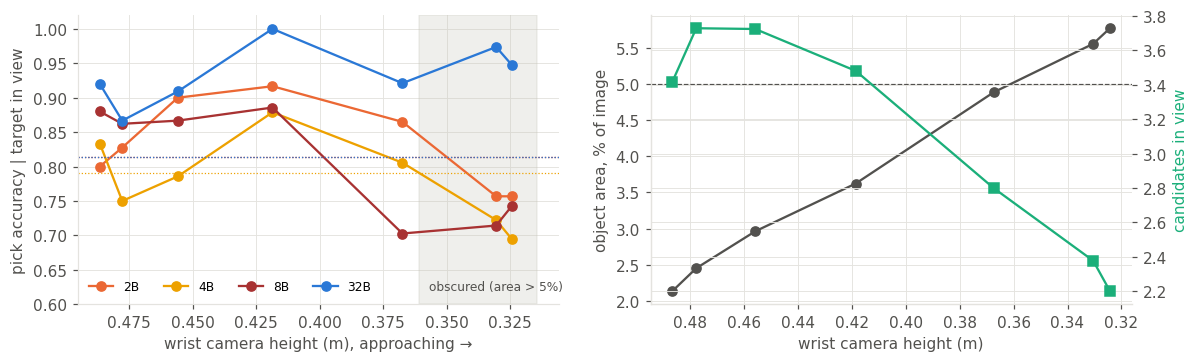

Dotted lines: the same model on the external view. Grey: views the gate treats as obscured.

In [11]:
PROBE = {}
for s in ['2b', '4b', '8b', '32b']:
    R = load(f'dev_probe2_{s}')
    if not R: continue
    st = collections.OrderedDict()
    for r in R:
        lab = {int(k): v for k, v in r['prop_labels'].items()}; tid = next((k for k, v in lab.items() if v == r['target_name']), None)
        for v in r.get('views', []):
            d = st.setdefault(v['stage'], dict(n=0, vis=0, pick=0, pos=[], neg=[]))
            d['n'] += 1
            if tid is None or tid not in v['visible']: continue
            d['vis'] += 1; d['pick'] += v['choice'] == tid
            for k, x in v['yes'].items(): (d['pos'] if int(k) == tid else d['neg']).append(x)
    PROBE[s] = st
def _auc(p, n): return np.mean([(a > b) + 0.5 * (a == b) for a in p for b in n]) if p and n else np.nan
if PROBE:
    stages = list(next(iter(PROBE.values())).keys())
    rows = [[s.upper()] + [f"{PROBE[s][k]['pick']/max(PROBE[s][k]['vis'],1):.2f} / {_auc(PROBE[s][k]['pos'], PROBE[s][k]['neg']):.2f} ({PROBE[s][k]['vis']})" for k in stages] for s in PROBE]
    display(Markdown('**Dev probe (43 episodes per model).** Each cell: VLM pick accuracy when the target is in view / Yes-No AUC (episodes with the target in view). Stages go from the external camera, through 6 checkpoints on the approach, to the look pose 22 cm above the object.'))
    table(rows, ['Model'] + stages)
    # accuracy vs camera height, with the view features that mark the obscurity point
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.4)); col = {'2b': '#eb6834', '4b': '#eda100', '8b': '#a83232', '32b': '#2a78d6'}
    feats = collections.defaultdict(lambda: collections.defaultdict(list))
    for s in PROBE:
        for r in load(f'dev_probe2_{s}'):
            for v in r.get('views', []):
                if v['stage'] == 'ext': continue
                q = v.get('quality', {}).get(str(r['initial_choice']))
                if q: feats[v['stage']]['h'].append(v['height']); feats[v['stage']]['area'].append(q['area']); feats[v['stage']]['n'].append(len(v['visible']))
    wst = [k for k in stages if k != 'ext']; H = [np.median(feats[k]['h']) for k in wst]
    for s, st in PROBE.items():
        axs[0].plot(H, [st[k]['pick'] / max(st[k]['vis'], 1) for k in wst], marker='o', color=col[s], label=s.upper())
        axs[0].axhline(st['ext']['pick'] / max(st['ext']['vis'], 1), color=col[s], ls=':', lw=0.8)
    A5 = [np.median(feats[k]['area']) for k in wst]; i = next((j for j in range(1, len(A5)) if A5[j] > 0.05 >= A5[j - 1]), None)
    h5 = H[i - 1] + (0.05 - A5[i - 1]) / (A5[i] - A5[i - 1]) * (H[i] - H[i - 1]) if i else min(H)   # height where the median area crosses 5%
    axs[0].axvspan(min(H) - 0.01, h5, color='#c3c2b7', alpha=0.25); axs[0].text(h5 - 0.004, 0.62, 'obscured (area > 5%)', fontsize=8, color=INK2, ha='left')
    axs[0].invert_xaxis(); axs[0].set_xlabel('wrist camera height (m), approaching →'); axs[0].set_ylabel('pick accuracy | target in view'); axs[0].legend(ncol=4, fontsize=8); axs[0].set_ylim(0.6, 1.02)
    axs[1].plot(H, [100 * np.median(feats[k]['area']) for k in wst], marker='o', color=INK2, label='approached object, % of image')
    ax2 = axs[1].twinx(); ax2.plot(H, [np.mean(feats[k]['n']) for k in wst], marker='s', color='#1baf7a', label='candidates in view'); ax2.set_ylabel('candidates in view', color='#1baf7a')
    axs[1].axhline(5, color=INK2, ls='--', lw=0.8); axs[1].invert_xaxis(); axs[1].set_xlabel('wrist camera height (m)'); axs[1].set_ylabel('object area, % of image')
    plt.tight_layout(); plt.show()
    display(Markdown('Dotted lines: the same model on the external view. Grey: views the gate treats as obscured.'))

In [12]:
# Eval: one-shot baseline (section 4) vs reactive configs
RX = [('one-shot (sec. 4)', 'e3_qwen3vl-{s}'), ('ens1, K=2', 'rx_{s}_ens1_K2'), ('ens3, K=0', 'rx_{s}_ens3_K0'), ('ens3, K=2', 'rx_{s}_ens3_K2'),
      ('ens3, K=4', 'rx_{s}_ens3_K4'), ('gate, last', 'rx_{s}_gate_last'), ('gate, vote', 'rx_{s}_gate_vote')]
SZ = ['2b', '4b', '8b', '32b']
def vlm_cost(R, s, run):
    if 'vlm_sec' in (R[0] if R else {}): return np.mean([r.get('vlm_sec', 0) for r in R]), np.mean([r.get('n_vlm', 0) for r in R])
    m = BEST.get(f'qwen3vl-{s}'); return (PROF[f'qwen3vl-{s}'][f'{m}_s_median'], 1.0) if PROF and m else (np.nan, 1.0)
rows, PTS = [], collections.defaultdict(list)
for s in SZ:
    for lab, pat in RX:
        run = pat.format(s=s); R = load(run)
        if not R: rows.append([s.upper(), lab, 'pending', '', '', '', '']); continue
        sec, nq = vlm_cost(R, s, run)
        corr = sum(1 for r in R if r.get('initial_correct') is False and r.get('grounding_correct')); regr = sum(1 for r in R if r.get('initial_correct') and not r.get('grounding_correct'))
        rows.append([s.upper(), lab, fmt(R, 'grounding_correct'), fmt(R), f'{sec:.2f} s', f'{nq:.1f}', f'+{corr} / −{regr}' if 'initial_correct' in R[0] else '–'])
        PTS[s].append((sec, rate(R)['sr'], rate(R, 'grounding_correct')['sr'], lab))
table(rows, ['Model', 'Policy', 'Final grounding correct', 'Pick success', 'VLM compute / episode', 'VLM calls / episode', 'Corrected / broken vs first answer'])

| Model | Policy | Final grounding correct | Pick success | VLM compute / episode | VLM calls / episode | Corrected / broken vs first answer |
|---|---|---|---|---|---|---|
| 2B | one-shot (sec. 4) | 73.9% [68–79] (n=257) | 63.4% [57–69] (n=257) | 0.29 s | 1.0 | – |
| 2B | ens1, K=2 | 73.2% [67–78] (n=257) | 63.8% [58–69] (n=257) | 1.56 s | 2.6 | +15 / −24 |
| 2B | ens3, K=0 | 79.4% [74–84] (n=257) | 65.8% [60–71] (n=257) | 1.39 s | 3.0 | +0 / −0 |
| 2B | ens3, K=2 | 80.9% [76–85] (n=257) | 68.9% [63–74] (n=257) | 2.82 s | 4.6 | +14 / −6 |
| 2B | ens3, K=4 | 78.2% [73–83] (n=257) | 65.8% [60–71] (n=257) | 3.38 s | 6.0 | +10 / −8 |
| 2B | gate, last | 72.8% [67–78] (n=257) | 62.6% [57–68] (n=257) | 2.25 s | 4.0 | +13 / −24 |
| 2B | gate, vote | 79.0% [74–84] (n=257) | 66.9% [61–72] (n=257) | 3.13 s | 5.8 | +11 / −9 |
| 4B | one-shot (sec. 4) | 75.5% [70–80] (n=257) | 64.2% [58–70] (n=257) | 0.46 s | 1.0 | – |
| 4B | ens1, K=2 | 78.6% [73–83] (n=257) | 65.0% [59–71] (n=257) | 1.94 s | 2.5 | +10 / −9 |
| 4B | ens3, K=0 | 82.9% [78–87] (n=257) | 68.5% [63–74] (n=257) | 1.55 s | 3.0 | +0 / −0 |
| 4B | ens3, K=2 | 86.0% [81–90] (n=257) | 71.6% [66–77] (n=257) | 2.99 s | 4.6 | +9 / −2 |
| 4B | ens3, K=4 | 85.2% [80–89] (n=257) | 70.8% [65–76] (n=257) | 3.78 s | 6.0 | +12 / −3 |
| 4B | gate, last | 73.9% [68–79] (n=257) | 61.1% [55–67] (n=257) | 2.73 s | 3.7 | +8 / −14 |
| 4B | gate, vote | 81.7% [77–86] (n=257) | 69.6% [64–75] (n=257) | 2.97 s | 5.9 | +9 / −5 |
| 8B | one-shot (sec. 4) | 74.7% [69–80] (n=257) | 64.2% [58–70] (n=257) | 0.28 s | 1.0 | – |
| 8B | ens1, K=2 | 74.7% [69–80] (n=257) | 62.3% [56–68] (n=257) | 2.02 s | 2.5 | +14 / −21 |
| 8B | ens3, K=0 | 80.9% [76–85] (n=257) | 67.3% [61–73] (n=257) | 1.73 s | 3.0 | +0 / −0 |
| 8B | ens3, K=2 | 82.9% [78–87] (n=257) | 69.6% [64–75] (n=257) | 3.03 s | 4.6 | +7 / −4 |
| 8B | ens3, K=4 | 81.3% [76–86] (n=257) | 67.7% [62–73] (n=257) | 3.68 s | 5.9 | +10 / −8 |
| 8B | gate, last | 71.6% [66–77] (n=257) | 60.3% [54–66] (n=257) | 2.34 s | 3.8 | +12 / −28 |
| 8B | gate, vote | 82.9% [78–87] (n=257) | 69.6% [64–75] (n=257) | 3.51 s | 5.9 | +7 / −7 |
| 32B | one-shot (sec. 4) | 80.9% [76–85] (n=257) | 68.1% [62–73] (n=257) | 0.23 s | 1.0 | – |
| 32B | ens1, K=2 | 80.5% [75–85] (n=257) | 67.7% [62–73] (n=257) | 0.79 s | 2.6 | +9 / −11 |
| 32B | ens3, K=0 | 80.5% [75–85] (n=257) | 67.7% [62–73] (n=257) | 3.51 s | 3.0 | +0 / −0 |
| 32B | ens3, K=2 | 84.0% [79–88] (n=257) | 71.6% [66–77] (n=257) | 4.08 s | 4.6 | +6 / −5 |
| 32B | ens3, K=4 | 84.8% [80–89] (n=257) | 70.8% [65–76] (n=257) | 4.35 s | 6.0 | +10 / −5 |
| 32B | gate, last | 77.8% [72–82] (n=257) | 65.0% [59–71] (n=257) | 1.20 s | 3.8 | +12 / −18 |
| 32B | gate, vote | 83.7% [79–88] (n=257) | 71.2% [65–76] (n=257) | 4.15 s | 5.9 | +10 / −3 |


Lines: one-shot → 3 modes on the external view → + 2 → + 4 approach re-asks. Markers: single-mode re-asks (×), gated "last view decides" (▼), gated vote (■).

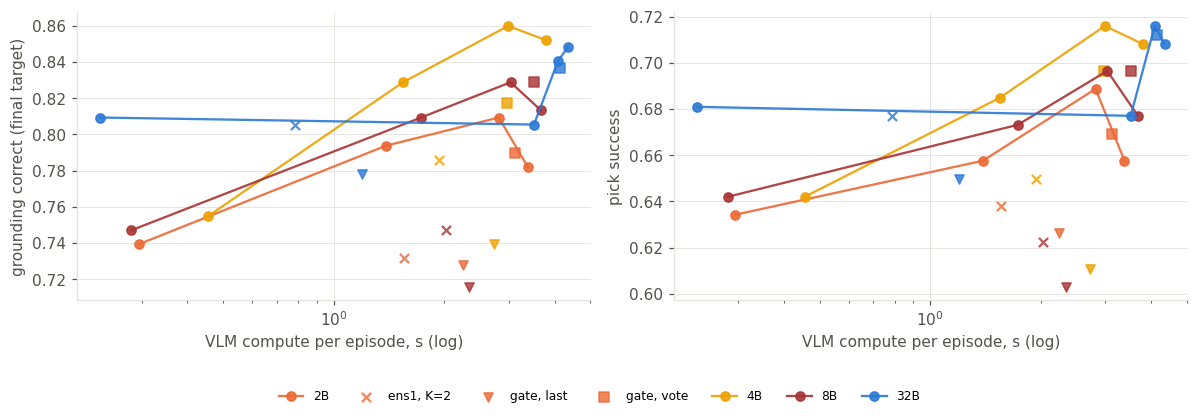

In [13]:
if PTS:
    fig, axs = plt.subplots(1, 2, figsize=(11, 3.6)); col = {'2b': '#eb6834', '4b': '#eda100', '8b': '#a83232', '32b': '#2a78d6'}
    MAIN = ['one-shot (sec. 4)', 'ens3, K=0', 'ens3, K=2', 'ens3, K=4']; MK = {'ens1, K=2': 'x', 'gate, last': 'v', 'gate, vote': 's'}
    for s, pts in PTS.items():
        P_ = {p[3]: p for p in pts}; main = [P_[k] for k in MAIN if k in P_]
        for ax, j in zip(axs, (2, 1)):
            ax.plot([p[0] for p in main], [p[j] for p in main], marker='o', color=col[s], label=s.upper(), alpha=0.9)
            for k, mk in MK.items():
                if k in P_: ax.scatter(P_[k][0], P_[k][j], marker=mk, color=col[s], s=36, alpha=0.8, label=k if s == '2b' else None)
    for ax, yl in zip(axs, ('grounding correct (final target)', 'pick success')):
        ax.set_xscale('log'); ax.set_xlabel('VLM compute per episode, s (log)'); ax.set_ylabel(yl)
    fig.legend(*axs[1].get_legend_handles_labels(), fontsize=8, ncol=7, loc='lower center', bbox_to_anchor=(0.5, -0.06))
    display(Markdown('Lines: one-shot → 3 modes on the external view → + 2 → + 4 approach re-asks. Markers: single-mode re-asks (×), gated "last view decides" (▼), gated vote (■).'))
    plt.tight_layout(rect=(0, 0.06, 1, 1)); plt.show()

**Reading section 5.**
* **More inference beats a bigger model, if the answers are pooled.** Asking all three modes on the external view and then re-asking twice along the approach (ens3, K=2; about 4.6 calls and 3 s of VLM compute per episode) works for every size:

  | Model | Grounding, one-shot → ens3 K=2 | Pick success, one-shot → ens3 K=2 |
  |---|---|---|
  | 2B | 74% → 81% | 63% → 69% |
  | 4B | 76% → **86%** | 64% → **72%** |
  | 8B | 75% → 83% | 64% → 70% |
  | 32B | 81% → 84% | 68% → 72% |

  **4B with ens3 K=2 is better than 32B one-shot (86% vs 81% grounding) at 8 GB of GPU memory instead of 62 GB.** The gain on the success CIs (about ±6 points) is clear for 4B and borderline for the others.
* **Most of the gain comes from the three modes on the external view (ens3, K=0, +5–7 points of grounding for 2B–8B).** Their errors are partly independent, while a repeated query in the same mode is deterministic. The two approach re-asks add 2–3 more points. Four re-asks add nothing over two: the extra checkpoints fall in the close range where views get worse.
* **Re-asking with a single mode hurts the small models.** ens1, K=2 breaks more correct first answers than it fixes (2B +15/−24, 8B +14/−21): one external vote is easily outvoted by a noisy wrist view. With three external votes, wrong wrist views rarely flip a correct answer (2B +14/−6, 4B +9/−2).
* **The obscured-view gate is real per view, but "the last unobscured view decides" does not work as a decision rule.** It is worse than one-shot for every model (2B 73%, 4B 74%, 8B 72%, 32B 78% grounding), breaking 14–28 correct answers per run. Two reasons:
  * single wrist picks are wrong 10–25% of the time even in good views, so letting one view decide replaces a pooled answer with one noisy sample;
  * an absolute area threshold fires late for small objects and early for large ones (in about half the broken 2B episodes it never fired).
  
  As a filter inside the vote (gate, vote), it is on par with the ungated vote (within ±3 points). Planning the grasp from the last uncut detection when the close-up is cut by the border triggered in 6–9 episodes per run, mostly the banana, scissors and clamp. It never helped: those grasps fail either way.
* **The limit of correcting on the way:** the arm heads to its first choice, so in about 1 episode in 5 the true target never enters the wrist view, and no rule can fix that. The next step would be active viewing: when the external votes disagree, move first to a view that covers all the disagreeing candidates.

---
## 6. Videos

External camera, 20 fps.

**Side by side: the same scene and target under two configs.** Episodes were picked from the evaluation results to illustrate each failure type, then re-recorded with `run_isaac --episodes` (`tools/isaac/queue_demo.sh`). Each rerun gave the same outcome as in the evaluation.

In [14]:
CMP = [('look_bleach', 'Wrist look. Without it, the grasp is planned from the external camera\'s one-sided view of the bleach bottle and the fingers come down on it (`approach_collision`); with the look, the grasp is re-planned from above.'),
       ('look_mustard', 'Same, for the mustard bottle.'),
       ('ik_pudding', 'Controller. Isaac\'s differential IK stalls about 5 cm short with the hand tilted (`reach`); our planned IK goes there in a straight line.'),
       ('vlm_gelatin', 'VLM. Asked for the gelatin box, the 2B model points at the mustard bottle; the 32B model picks the right one. The grasp itself is the same.'),
       ('slip_clamp', 'Grasp. The clamp is grasped but slips out when lifted (`grasp_slip`), the most common failure for this object.')]
for name, cap in CMP:
    show(f'{ROOT}/demo/franka/compare/{name}.mp4', w=900, caption=f'**{name}**: {cap}')

**look_bleach**: Wrist look. Without it, the grasp is planned from the external camera's one-sided view of the bleach bottle and the fingers come down on it (`approach_collision`); with the look, the grasp is re-planned from above.

**look_mustard**: Same, for the mustard bottle.

**ik_pudding**: Controller. Isaac's differential IK stalls about 5 cm short with the hand tilted (`reach`); our planned IK goes there in a straight line.

**vlm_gelatin**: VLM. Asked for the gelatin box, the 2B model points at the mustard bottle; the 32B model picks the right one. The grasp itself is the same.

**slip_clamp**: Grasp. The clamp is grasped but slips out when lifted (`grasp_slip`), the most common failure for this object.

**First evaluation episodes, chosen by rule (episode order), not by outcome.** One clip per config, plus the 32B closed-loop run.

In [15]:
for name in ['e1_a_extonly', 'e1_b_refine', 'e1_c_fixedyaw', 'e1_d_joint', 'e1_e_native', 'e1_f_gtseg', 'e3_qwen3vl-32b']:
    for v in sorted(glob.glob(f'{ROOT}/demo/franka/{name}/*.mp4'))[:1]:
        show(v, w=420, caption=f'**{name}**: `{os.path.basename(v)}`')

**e1_a_extonly**: `100_004_sugar_box_ok.mp4`

**e1_b_refine**: `100_004_sugar_box_ok.mp4`

**e1_c_fixedyaw**: `100_004_sugar_box_fail.mp4`

**e1_d_joint**: `100_004_sugar_box_ok.mp4`

**e1_e_native**: `100_004_sugar_box_fail.mp4`

**e1_f_gtseg**: `100_004_sugar_box_ok.mp4`

**e3_qwen3vl-32b**: `100_004_sugar_box_ok.mp4`

---
## 7. Moving to the real Franka

What is already shared:
* the episode loop, perception, VLM grounding, grasp planner and IK (`vrg/franka/*`);
* `real_franky.py`, which implements the same interface with franky and two RealSense cameras.

Before the first real run:
1. **Calibrate.** External camera → base (a ChArUco board held by the robot, or `easy_handeye2`), and wrist camera → TCP (hand-eye). Both go in `calib.json`. The sim's camera poses are the defaults to mimic.
2. **Desk end effector** = Franka Hand, so franky's `O_T_EE` is the TCP used here (0.1034 m, −45°).
3. **Dry run** (`dry_run=True`): perception + VLM + grasp planning on live images, motions disabled, and check the planned grasps overlaid on the image.
4. **Slow first motions**: `relative_dynamics_factor = 0.05`, workspace bounds in `perception.Workspace` set to the real table.
5. **Depth noise**: RealSense depth is noisier than the simulator's at object edges. The look-then-grasp wrist view (≈ 30 cm range) is the main defence, and D405-class close-range cameras are a good fit for the wrist.

Sim-to-real gaps to expect: depth noise and missing depth on shiny or transparent surfaces, camera calibration error (a few mm to 1 cm), contact physics of the soft fingertips, and object weights.

---
## 8. Summary

| Question | Answer (257 eval episodes, 13 YCB targets, 6 objects per scene) |
|---|---|
| How good is the scripted grasp with a perfect VLM? | **78%** with a wrist look-then-grasp (49% from the external camera alone). |
| Better controller? | Our planned IK (goal IK with limits, null-space posture and restarts, then min-jerk joints plus straight-line approach and lift) converges where Isaac's one-step differential IK stalls or swings into the object: **78% vs 56%** (both are about 3 mm accurate when they converge). Pure joint moves are on par in sim (77%). |
| Does a bigger VLM help? | Little from 2B to 8B (75–78% grounding, 63–64% end to end); **32B: 81% grounding, 68% end to end**, at 62 GB of GPU memory. Set-of-marks scales best and is fastest (0.23 s per query with 32B, about 5× slower than with 2B). |
| Can repeated inference replace a bigger model? | **Yes, when pooled.** 3 modes on the external view + 2 re-asks along the approach: 4B reaches **86% grounding / 72% success** (32B one-shot: 81% / 68%). Re-asking a single mode, or letting the last view decide (even gated for obscured views), hurts. |
| Is the VLM or the grasp failing? | **The VLM**, with grounding errors 14–21% of episodes. Given correct grounding, the robot side succeeds about 85% for every model. Robot-side failures (11–13%) are mostly top-down grasps of objects wider than the hand. |

**Next steps:**
* Robot side: side or edge grasps for wide or flat objects (the cracker box), and better segmentation of thin objects (the scissors).
* VLM side: pooled multi-mode grounding plus a few re-asks along the approach (section 5) is the default to carry to the real arm. Next comes active viewing, moving to a view that covers the candidates the votes disagree on.
* Real arm: the checklist in section 7. The episode code runs unchanged on `FrankyRobot`.